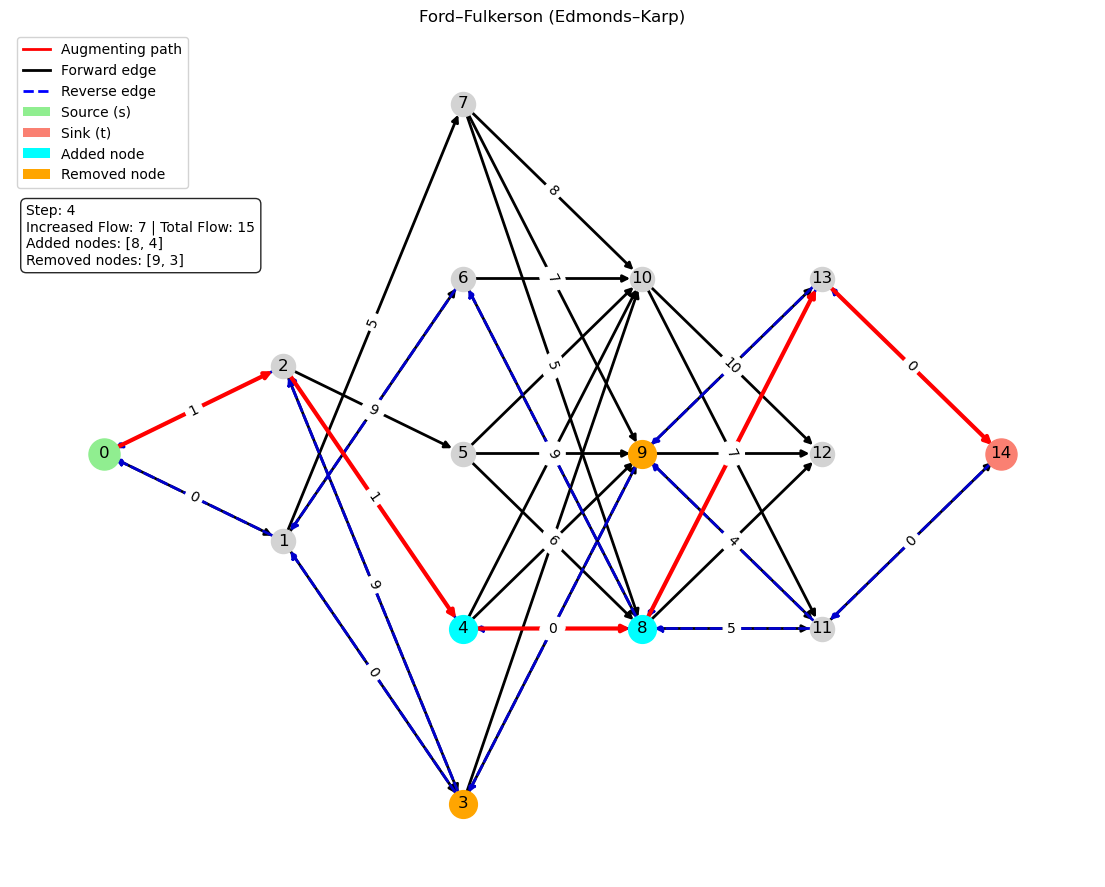

In [ ]:
import networkx as nx
from collections import deque
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import random, copy, math
import numpy as np
from sklearn.cluster import KMeans


def bfs(residual, s, t):
    parent = {s: None}
    q = deque([s])

    added_nodes = [] 
    
    while q:
        u = q.popleft()
        for v in residual[u]:
            if v not in parent and residual[u][v]['capacity'] > 0:
                parent[v] = u
                added_nodes.append(v)  
                if v == t:
                    return parent, added_nodes
                q.append(v)
    return None, added_nodes


def ford_fulkerson_steps(G, s, t):
    residual = nx.DiGraph()
    for u, v, data in G.edges(data=True):
        residual.add_edge(u, v, capacity=data['capacity'])
        residual.add_edge(v, u, capacity=0)

    steps = []
    flow = 0

    while True:
        parent, added_nodes = bfs(residual, s, t)
        if parent is None:
            break
        removed_nodes = list(parent.keys())

        path = []
        bottleneck = float('inf')
        v = t
        while v != s:
            u = parent[v]
            path.append((u, v))
            bottleneck = min(bottleneck, residual[u][v]['capacity'])
            v = u
        path.reverse()

        for u, v in path:
            residual[u][v]['capacity'] -= bottleneck
            residual[v][u]['capacity'] += bottleneck

        flow += bottleneck

        steps.append({
            'path': path,
            'flow': bottleneck,
            'residual': copy.deepcopy(residual),
            'total_flow': flow,
            'added_nodes': added_nodes,
            'removed_nodes': removed_nodes
        })

    return steps



def draw_step(G, step, pos, step_num):
    plt.figure(figsize=(7, 5))

    residual = step['residual']
    path_edges = set(step['path'])

    edge_labels = {}
    edge_colors = []

    for u, v in G.edges():
        cap = residual[u][v]['capacity']
        edge_labels[(u, v)] = cap
        edge_colors.append('red' if (u, v) in path_edges else 'black')

    nx.draw(
        G, pos,
        with_labels=True,
        edge_color=edge_colors,
        node_size=2000,
        node_color='lightgray',
        width=2
    )

    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

    plt.show()
    return True


prev_path_nodes = set()  # start empty


def ensure_st_path_directed(G, s, t, cap_range=(5, 10)):
    if not nx.has_path(G, s, t):
        # Use BFS/DFS on undirected version to find a path
        UG = G.to_undirected()
        path = nx.shortest_path(UG, s, t)
        for u, v in zip(path[:-1], path[1:]):
            # Add edge in the "correct" direction if missing
            if not G.has_edge(u, v):
                G.add_edge(u, v, capacity=random.randint(*cap_range))
            # Also optionally add reverse edge to keep BFS exploring options
            if not G.has_edge(v, u):
                G.add_edge(v, u, capacity=0)
    return G

def layered_layout(G, s):
    levels = {}
    visited = {s}
    queue = [(s, 0)]

    while queue:
        node, level = queue.pop(0)
        levels[node] = level
        for neighbor in G.successors(node):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append((neighbor, level + 1))

    pos = {}
    layer_counts = {}
    for node, level in levels.items():
        layer_counts[level] = layer_counts.get(level, 0) + 1

    layer_positions = {}
    for level, count in layer_counts.items():
        xs = list(range(count))
        layer_positions[level] = xs

    layer_indices = {}
    for node, level in levels.items():
        idx = layer_positions[level].pop(0)
        pos[node] = (level, idx)

    return pos

def update(frame):
    global prev_path_nodes
    ax.clear()
    step = steps[frame]

    # Current augmenting path nodes
    current_path_nodes = set(u for edge in step['path'] for u in edge)

    # Compute added / removed nodes
    added_nodes = current_path_nodes - prev_path_nodes
    removed_nodes = prev_path_nodes - current_path_nodes

    # Update previous path nodes for next iteration
    prev_path_nodes = current_path_nodes.copy()

    # Draw the network nodes
    nx.draw_networkx_nodes(G, pos, node_size=300, node_color='lightgray', ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=added_nodes, node_color='cyan', node_size=400, ax=ax, label='Added node')
    nx.draw_networkx_nodes(G, pos, nodelist=removed_nodes, node_color='orange', node_size=400, ax=ax, label='Removed node')
    nx.draw_networkx_nodes(G, pos, nodelist=[s], node_color='lightgreen', node_size=500, ax=ax, label='Source (s)')
    nx.draw_networkx_nodes(G, pos, nodelist=[t], node_color='salmon', node_size=500, ax=ax, label='Sink (t)')
    nx.draw_networkx_labels(G, pos, ax=ax)

    # Draw edges (forward, reverse, augmenting)
    path_edges = set(step['path'])
    forward_edges = [(u, v) for u, v in G.edges() if (u, v) not in path_edges]
    reverse_edges = [(u, v) for u, v in step['residual'].edges() if (u, v) not in G.edges() and step['residual'][u][v]['capacity'] > 0]

    nx.draw_networkx_edges(G, pos, edgelist=forward_edges, edge_color='black', width=2, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=reverse_edges, edge_color='mediumblue', style='dashed', width=2, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=list(path_edges), edge_color='red', width=3, ax=ax)

    # Draw edge labels
    edge_labels = {(u, v): step['residual'][u][v]['capacity'] for u, v in G.edges()}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, ax=ax)

    # Flow info text
    flow_text_str = (
        f"Step: {frame+1}\n"
        f"Increased Flow: {step['flow']} | Total Flow: {step['total_flow']}\n"
        f"Added nodes: {list(added_nodes)}\n"
        f"Removed nodes: {list(removed_nodes)}"
    )
    ax.text(0.015, 0.72, flow_text_str, transform=ax.transAxes, fontsize=10,
            verticalalignment='bottom', bbox=dict(boxstyle="round,pad=0.4", fc="white", alpha=0.85))

    ax.set_title("Ford–Fulkerson (Edmonds–Karp)")
    ax.axis('off')
    ax.legend(handles=legend_elements, loc='upper left', frameon=True, framealpha=0.85, fontsize=10)
    return True



def generate_multipartite_graph(layer_sizes, edge_prob=0.5, directed=True):
    """
    Generate a k-partite graph.
    
    Parameters
    ----------
    layer_sizes : list[int]
        Number of nodes in each layer.
    edge_prob : float
        Probability of an edge between nodes in consecutive layers.
    directed : bool
        Whether the graph is directed (default True)
    
    Returns
    -------
    G : networkx.DiGraph or Graph
        Multipartite graph with 'subset' attribute per node.
    """
    G = nx.DiGraph() if directed else nx.Graph()
    
    node_counter = 0
    layers = []
    
    for subset, size in enumerate(layer_sizes):
        layer_nodes = list(range(node_counter, node_counter + size))
        for n in layer_nodes:
            G.add_node(n, subset=subset)
        layers.append(layer_nodes)
        node_counter += size
    
    # Connect nodes between consecutive layers
    for i in range(len(layers)-1):
        for u in layers[i]:
            for v in layers[i+1]:
                if random.random() < edge_prob:
                    G.add_edge(u, v)
    
    return G

layer_sizes = [1, 2, 5, 3, 3, 1]  
G = generate_multipartite_graph(layer_sizes, edge_prob=0.8)

pos = nx.multipartite_layout(G, subset_key='subset', align='vertical', scale=2)

subset0 = [n for n, d in G.nodes(data=True) if d['subset']==0]
subsetk = [n for n, d in G.nodes(data=True) if d['subset']==len(layer_sizes)-1]
s = random.choice(subset0)
t = random.choice(subsetk)

G = ensure_st_path_directed(G, s, t)
for u, v in G.edges():
    G[u][v]['capacity'] = random.randint(5, 10)


steps = ford_fulkerson_steps(G, s, t)
if not steps:
    raise ValueError("No augmenting path found — animation aborted.")

fig, ax = plt.subplots(figsize=(14, 11))
legend_elements = [
    Line2D([0], [0], color='red', lw=2, label='Augmenting path'),
    Line2D([0], [0], color='black', lw=2, label='Forward edge'),
    Line2D([0], [0], color='blue', lw=2, linestyle='--', label='Reverse edge'),
    Patch(facecolor='lightgreen', label='Source (s)'),
    Patch(facecolor='salmon', label='Sink (t)'),
    Patch(facecolor='cyan', label='Added node'),
    Patch(facecolor='orange', label='Removed node')
]
ani = FuncAnimation(
    fig,
    update,
    frames=len(steps),
    interval=1500,
    repeat=False
)
ani.save(
    "ford_fulkerson_steps.gif",
    writer="pillow",
    fps=0.2
)
plt.show()




In [5]:
nx.write_gml(G, "ford_fulkerson_graph.gml")


In [ ]:
nx.read_gml("ford_fulkerson_graph.gml"

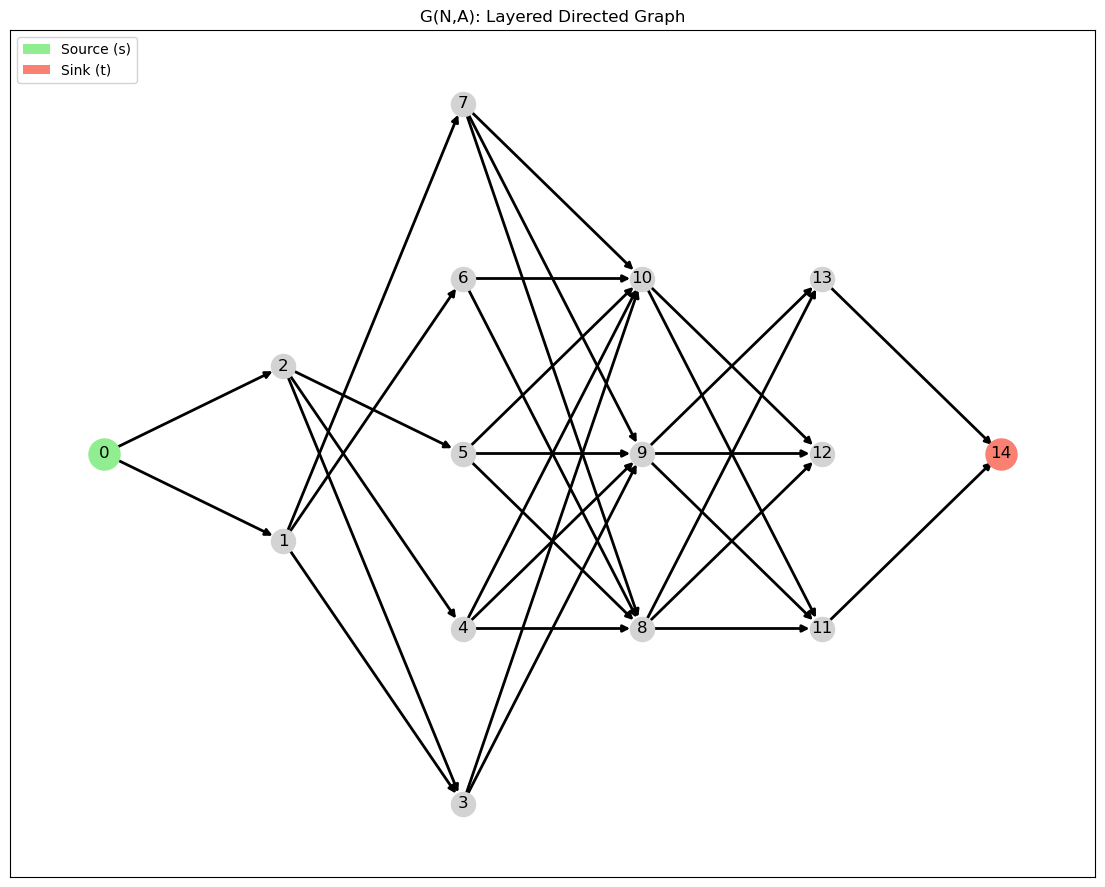

In [12]:
fig, ax = plt.subplots(figsize=(14, 11))
legend_elements = [
    Patch(facecolor='lightgreen', label='Source (s)'),
    Patch(facecolor='salmon', label='Sink (t)'),
]
nx.draw_networkx_nodes(G, pos, node_size=300, node_color='lightgray', ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=[s], node_color='lightgreen', node_size=500, ax=ax, label='Source (s)')
nx.draw_networkx_nodes(G, pos, nodelist=[t], node_color='salmon', node_size=500, ax=ax, label='Sink (t)')
nx.draw_networkx_labels(G, pos, ax=ax)
nx.draw_networkx_edges(G, pos, edge_color='black', width=2, ax=ax)
ax.set_title("G(N,A): Layered Directed Graph")
ax.legend(handles=legend_elements, loc='upper left', frameon=True, framealpha=0.85, fontsize=10)
plt.savefig("Network.png", bbox_inches='tight')
plt.show()